# COS40007 Artificial Intelligence Engineering
## Portfolio Assessment 3: Advanced ML – Classification using ML and Deep Learning
### Option 3c – LSTM for Classification

| | |
|---|---|
| **Student name** | Dinh Phu Nguyen |
| **Student ID** | 105027282 |
| **Date** | 11/1/2026 |
| **Dataset** | Appliances Energy Prediction – Candanedo, L. (2017), UCI Machine Learning Repository, DOI: [10.24432/C5VC8G](https://doi.org/10.24432/C5VC8G) |
| **GitHub** | [https://github.com/phu1009/COS40007---AI-Engineering-] |

**GenAI declaration:** I used Claude (Anthropic) in choosing option 3c, analysing the instructions and rubric and suggest the plan to do the Assignment, and organising and formatting the report. The full GenAI reflection (Part E) is in the PDF report.

## Problem definition and choice of option 3c
The dataset (cleaned in PA1, used for classification in PA2) contains **19,735 readings taken every 10 minutes** (11 January – 27 May 2016) of the appliance energy use of a low-energy house, together with indoor temperature and humidity sensors and outdoor weather data. The target is the **consumption class** defined in PA2 Task 1:

| Class | Appliances (Wh per 10 min) | Meaning (PA1 §3.3) |
|---|---|---|
| Low (0) | ≤ 50 | night-time base load |
| Medium (1) | 60–80 | light daytime activity |
| High (2) | ≥ 90 | high-power appliances, e.g. cooking in the evening peak |

The data is a **real time series** (sensor data) and the target is **categorical**, so the selection table of the instructions points to **option 3c – LSTM for Classification**.

### Design decisions kept fixed for Part A and Part B
| Decision | Choice | Reason |
|---|---|---|
| Features | 24 cleaned predictors + `hour_sin`, `hour_cos` (26) | the sensors are what the house measures; the time encoding captures the daily routine (PA2 Task 3: `hour_sin` was the most informative feature). No hand-made "change over time" features: learning temporal patterns from raw sequences is the job of the LSTM, so Part A vs Part B measures the value of temporal context |
| Split | **chronological 70/30** (train 11 Jan – 16 Apr, test 16 Apr – 27 May) | PA2 Task 10.2 showed that shuffled splits are optimistic for this time series; LSTM windows overlap, so a shuffled split would put near-identical windows in both sets |
| Test rows | the **same 5,921 test readings** for every model | fair comparison in Part C |

## 0. Setup

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # hide TensorFlow C++ info / warning messages

import time
import pickle
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, log_loss, classification_report,
                             ConfusionMatrixDisplay)
import tensorflow as tf
import keras
from keras import layers
from IPython.display import display

RANDOM_STATE = 42
TEST_SIZE = 0.30                     # chronological 70/30 split
N_FOLDS = 5                          # TimeSeriesSplit folds for Part A
CLASS_LABELS = ["Low", "Medium", "High"]
DATA_PATH = Path("data") / "energydata_complete.csv"
FIG_DIR, MODEL_DIR = Path("figures"), Path("models")
FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

# Reproducibility: same seed for numpy, Python and TensorFlow, deterministic TensorFlow operations
keras.utils.set_random_seed(RANDOM_STATE)
tf.config.experimental.enable_op_determinism()

sns.set_theme(style="whitegrid", context="notebook")
COLOR_MAIN, COLOR_SECOND, COLOR_THIRD, COLOR_GREY, COLOR_TEXT = "#2A78D6", "#E8683A", "#3A9D5D", "#B5B5AD", "#444444"
pd.set_option("display.precision", 4)


def save_fig(fig, name):
    """Save a figure for the report."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | TensorFlow {tf.__version__} | Keras {keras.__version__}")

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | TensorFlow 2.21.0 | Keras 3.15.1


# Part A – Traditional Machine Learning Models

## A.1 Load and analyse the dataset
The PA1 cleaning is applied: `date` is converted to datetime, and `rv1`, `rv2` (random noise columns, identical to each other) and `RH_6` (faulty outdoor humidity sensor) are removed. No rows are removed.

In [2]:
df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)
df = df.drop(columns=["rv1", "rv2", "RH_6"])

print(f"Shape after cleaning: {df.shape[0]:,} rows x {df.shape[1]} columns | missing values: {df.isna().sum().sum()}")
print(f"Period: {df['date'].iloc[0]} to {df['date'].iloc[-1]}")
print("Time step between readings:", df["date"].diff().value_counts().to_dict())

Shape after cleaning: 19,735 rows x 26 columns | missing values: 0
Period: 2016-01-11 17:00:00 to 2016-05-27 18:00:00
Time step between readings: {Timedelta('0 days 00:10:00'): 19734}


In [3]:
# Target: the three PA2 consumption classes (Low <= 50 Wh, Medium 60-80 Wh, High >= 90 Wh)
TARGET = "Appliances"
df["class"] = np.select([df[TARGET] <= 50, df[TARGET] <= 80], [0, 1], default=2)

# Time of day as a cyclic feature (23:50 and 00:00 are neighbours)
hour = df["date"].dt.hour + df["date"].dt.minute / 60
df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * hour / 24)

FEATURES = [c for c in df.columns if c not in ("date", TARGET, "class")]
print(f"Target '{TARGET}' is continuous (Wh), discretised into {len(CLASS_LABELS)} classes -> CLASSIFICATION problem")
print(f"{len(FEATURES)} features: {FEATURES}")

counts = df["class"].value_counts().sort_index()
display(pd.DataFrame({"class": CLASS_LABELS, "readings": counts.values,
                      "share (%)": (100 * counts / len(df)).round(1).values}).set_index("class"))

Target 'Appliances' is continuous (Wh), discretised into 3 classes -> CLASSIFICATION problem
26 features: ['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'hour_sin', 'hour_cos']


,readings,share (%)
class,,
Low,7462,37.8
Medium,6047,30.6
High,6226,31.5


## A.2 Preprocess the data
`X` and `y` are separated and split **chronologically** (`shuffle=False`): the first 70% of the period is used for training and the last 30% for testing. The **StandardScaler** is fitted on the training set only and then applied to both sets, so no information from the test period leaks into the preprocessing.

In [4]:
X = df[FEATURES].to_numpy()
y = df["class"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, shuffle=False)
CUT = len(X_train)                                     # index of the first test reading
dates_train, dates_test = df["date"].iloc[:CUT], df["date"].iloc[CUT:]

scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: X {X_train_scaled.shape}, y {y_train.shape} | {dates_train.iloc[0]:%d %b %Y} – {dates_train.iloc[-1]:%d %b %Y}")
print(f"Test set:     X {X_test_scaled.shape}, y {y_test.shape} | {dates_test.iloc[0]:%d %b %Y} – {dates_test.iloc[-1]:%d %b %Y}")
print(f"Scaled training features: mean {X_train_scaled.mean():.3f}, std {X_train_scaled.std():.3f}")

split_dist = pd.DataFrame({"train (%)": 100 * np.bincount(y_train) / len(y_train),
                           "test (%)": 100 * np.bincount(y_test) / len(y_test)}, index=CLASS_LABELS).round(1)
display(split_dist)

Training set: X (13814, 26), y (13814,) | 11 Jan 2016 – 16 Apr 2016
Test set:     X (5921, 26), y (5921,) | 16 Apr 2016 – 27 May 2016
Scaled training features: mean -0.000, std 1.000


,train (%),test (%)
Low,41.5,29.3
Medium,26.9,39.4
High,31.6,31.3


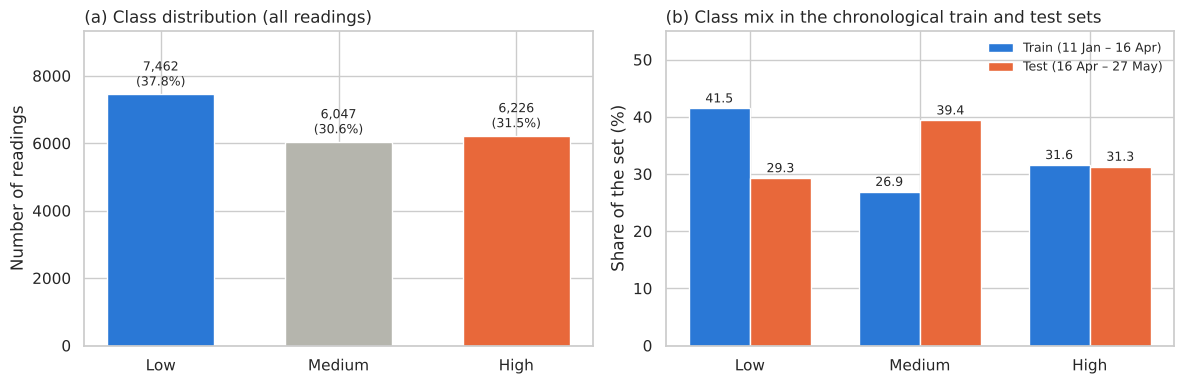

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bars = axes[0].bar(CLASS_LABELS, counts.values, color=[COLOR_MAIN, COLOR_GREY, COLOR_SECOND], width=0.6)
axes[0].bar_label(bars, labels=[f"{c:,}\n({100 * c / len(df):.1f}%)" for c in counts.values], padding=3, fontsize=9)
axes[0].set_ylim(0, counts.max() * 1.25)
axes[0].set_title("(a) Class distribution (all readings)", loc="left")
axes[0].set_ylabel("Number of readings")

x = np.arange(len(CLASS_LABELS))
b1 = axes[1].bar(x - 0.18, split_dist["train (%)"], width=0.36, color=COLOR_MAIN, label="Train (11 Jan – 16 Apr)")
b2 = axes[1].bar(x + 0.18, split_dist["test (%)"], width=0.36, color=COLOR_SECOND, label="Test (16 Apr – 27 May)")
axes[1].bar_label(b1, fmt="%.1f", padding=2, fontsize=9)
axes[1].bar_label(b2, fmt="%.1f", padding=2, fontsize=9)
axes[1].set_xticks(x, CLASS_LABELS)
axes[1].set_ylim(0, 55)
axes[1].set_ylabel("Share of the set (%)")
axes[1].set_title("(b) Class mix in the chronological train and test sets", loc="left")
axes[1].legend(frameon=False, loc="upper right", fontsize=9)
fig.tight_layout()
save_fig(fig, "pa3_A1_class_distribution")
plt.show()

### A.1–A.2 observations
- **Problem type:** the target `Appliances` is continuous, but it is used through the three PA2 classes, so this is a **3-class classification** problem. After cleaning there are 19,735 readings, 26 features and no missing values. The readings are exactly 10 minutes apart (19,734 steps of 10 minutes), so the data is a regular time series that can be cut into sequences for the LSTM.
- **Class balance:** overall 37.8% Low, 30.6% Medium and 31.5% High (balance ratio 0.81), so no class dominates.
- **Chronological split:** the 13,814 training readings cover 11 Jan – 16 Apr and the 5,921 test readings cover 16 Apr – 27 May. The **class mix shifts** between the two periods: Low falls from 41.5% to 29.3%, Medium rises from 26.9% to 39.4%, and High stays at about 31%. The most frequent training class (Low) is the least frequent test class, so the majority-class baseline only reaches 29.3%, below random guessing. Every model must cope with this seasonal shift (winter → spring), which makes the task harder than the shuffled split of PA2.
- **Scaling:** after the StandardScaler (fitted on the training set only) the training features have mean 0 and standard deviation 1. The test set is transformed with the training mean and standard deviation, as it would be for new data.

## A.3 Train two traditional ML models
| Model | Parameters | Reason |
|---|---|---|
| **Random Forest** | 300 trees, `min_samples_leaf = 5`, all features considered at random per split (`sqrt`) | averaging many de-correlated trees reduces the overfitting of the single Decision Trees in PA2 (100% training accuracy); a minimum of 5 readings per leaf smooths the leaves and keeps the saved model small |
| **MLP Classifier** | hidden layers (100, 50), ReLU, Adam, `alpha = 0.001`, `early_stopping = True`, `max_iter = 500` | starts from the course example `MLP_Classifcation.ipynb`; early stopping keeps 10% of the training data for validation and stops when it no longer improves; a small L2 penalty (`alpha`) limits overfitting |

A **majority-class baseline** (always predicts the most frequent training class) is added for reference. Both trained models and the scaler are saved as `.pkl` files.

In [6]:
models_A = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
    "MLP Classifier": MLPClassifier(hidden_layer_sizes=(100, 50), activation="relu", solver="adam", alpha=1e-3,
                                    early_stopping=True, max_iter=500, random_state=RANDOM_STATE),
}

fitted_A, pred_A, proba_A, time_A = {}, {}, {}, {}
for name, model in models_A.items():
    start = time.time()
    model.fit(X_train_scaled, y_train)
    time_A[name] = time.time() - start
    fitted_A[name] = model
    pred_A[name] = model.predict(X_test_scaled)
    proba_A[name] = model.predict_proba(X_test_scaled)
    print(f"{name:18s} trained in {time_A[name]:5.1f} s")

mlp = fitted_A["MLP Classifier"]
print(f"MLP stopped after {mlp.n_iter_} iterations (best validation score {mlp.best_validation_score_:.4f})")

Majority baseline  trained in   0.0 s


Random Forest      trained in   5.3 s


MLP Classifier     trained in   6.0 s
MLP stopped after 79 iterations (best validation score 0.7685)


In [7]:
# Save the traditional models (and the scaler they need) as .pkl files
for name, filename in [("Random Forest", "random_forest.pkl"), ("MLP Classifier", "mlp_classifier.pkl")]:
    joblib.dump(fitted_A[name], MODEL_DIR / filename, compress=3)
joblib.dump(scaler, MODEL_DIR / "standard_scaler.pkl")
for f in ["random_forest.pkl", "mlp_classifier.pkl", "standard_scaler.pkl"]:
    print(f"saved models/{f} ({(MODEL_DIR / f).stat().st_size / 1e6:.2f} MB)")

saved models/random_forest.pkl (13.65 MB)
saved models/mlp_classifier.pkl (0.19 MB)
saved models/standard_scaler.pkl (0.00 MB)


## A.4 Evaluate and compare
Metrics on the test period: **accuracy**, **F1-score (weighted average)** and the test **log loss** (cross-entropy, the same loss the LSTM minimises). Cross-validation uses **5-fold `TimeSeriesSplit`** on the training period: each fold trains on the past and validates on the following block, which respects the time order (a shuffled K-fold would mix past and future readings). Inside each fold the scaler is refitted with a pipeline.

In [8]:
tscv = TimeSeriesSplit(n_splits=N_FOLDS)
rows_A = []
for name, model in models_A.items():
    cv_scores = cross_val_score(make_pipeline(StandardScaler(), clone(model)), X_train, y_train, cv=tscv,
                                scoring="accuracy", n_jobs=1)
    rows_A.append({"model": name,
                   "test_accuracy": accuracy_score(y_test, pred_A[name]),
                   "weighted_F1": f1_score(y_test, pred_A[name], average="weighted"),
                   "macro_F1": f1_score(y_test, pred_A[name], average="macro"),
                   "test_log_loss": log_loss(y_test, proba_A[name], labels=[0, 1, 2]),
                   "cv_mean": cv_scores.mean(), "cv_std": cv_scores.std(),
                   "train_accuracy": accuracy_score(y_train, fitted_A[name].predict(X_train_scaled)),
                   "train_seconds": time_A[name]})
results_A = pd.DataFrame(rows_A).set_index("model")
best_A = results_A.drop("Majority baseline")["test_accuracy"].idxmax()

table_A = results_A.copy()
table_A["CV accuracy (5-fold TimeSeriesSplit)"] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(table_A.cv_mean, table_A.cv_std)]
table_A = table_A[["test_accuracy", "weighted_F1", "macro_F1", "test_log_loss", "CV accuracy (5-fold TimeSeriesSplit)",
                   "train_accuracy", "train_seconds"]]
table_A.columns = ["Test accuracy", "Weighted F1", "Macro F1", "Test log loss", "CV accuracy (5-fold TimeSeriesSplit)",
                   "Train accuracy", "Training time (s)"]
display(table_A.style.format({c: "{:.4f}" for c in ["Test accuracy", "Weighted F1", "Macro F1", "Test log loss", "Train accuracy"]}
                             | {"Training time (s)": "{:.1f}"})
        .highlight_max(subset=["Test accuracy", "Weighted F1"], color="#d6e6f8"))
print(f"Best traditional model on the test period: {best_A}")

,Test accuracy,Weighted F1,Macro F1,Test log loss,CV accuracy (5-fold TimeSeriesSplit),Train accuracy,Training time (s)
model,,,,,,,
Majority baseline,0.2930,0.1328,0.1511,25.4820,0.3850 ± 0.0547,0.4146,0.0
Random Forest,0.5128,0.5055,0.5069,0.9174,0.5903 ± 0.0371,0.8956,5.3
MLP Classifier,0.4849,0.4860,0.4857,1.4593,0.5793 ± 0.0618,0.8016,6.0


Best traditional model on the test period: Random Forest


In [9]:
for name in ["Random Forest", "MLP Classifier"]:
    print(f"--- {name} ---")
    print(classification_report(y_test, pred_A[name], target_names=CLASS_LABELS, digits=3))

--- Random Forest ---
              precision    recall  f1-score   support

         Low      0.532     0.356     0.427      1735
      Medium      0.452     0.488     0.469      2331
        High      0.570     0.691     0.625      1855

    accuracy                          0.513      5921
   macro avg      0.518     0.512     0.507      5921
weighted avg      0.513     0.513     0.506      5921

--- MLP Classifier ---
              precision    recall  f1-score   support

         Low      0.467     0.464     0.466      1735
      Medium      0.436     0.544     0.484      2331
        High      0.618     0.431     0.508      1855

    accuracy                          0.485      5921
   macro avg      0.507     0.479     0.486      5921
weighted avg      0.502     0.485     0.486      5921



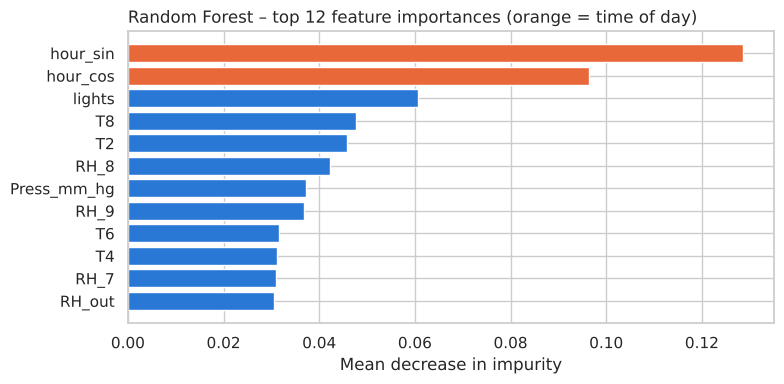

In [10]:
# Which sensors does the Random Forest rely on?
rf_importance = pd.Series(fitted_A["Random Forest"].feature_importances_, index=FEATURES).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
top = rf_importance.head(12)[::-1]
ax.barh(top.index, top.values, color=[COLOR_SECOND if f.startswith("hour") else COLOR_MAIN for f in top.index])
ax.set_title("Random Forest – top 12 feature importances (orange = time of day)", loc="left")
ax.set_xlabel("Mean decrease in impurity")
fig.tight_layout()
save_fig(fig, "pa3_A4_rf_importance")
plt.show()

### A.4 – Which model performed best and why?
- **Random Forest is the best traditional model:** test accuracy **51.28%**, weighted F1 **0.506** and log loss **0.917**, compared with 48.49%, 0.486 and 1.459 for the MLP. It is also better in the time-series cross-validation (59.0% ± 3.7 vs 57.9% ± 6.2) and varies less between folds.
- **Why the Random Forest wins:**
  - It averages 300 de-correlated trees, which cancels much of the noise of a single tree (PA2 trees reached 100% training accuracy).
  - It handles skewed sensors and interactions such as *time of day × lights* without any tuning.
  - Its most important features are `hour_sin` (0.129) and `hour_cos` (0.096), together 22% of the importance, followed by `lights` (0.061) and the living-room and bedroom sensors `T8`, `T2` and `RH_8`. This matches the daily routine found in PA1 §3.3.
- **The MLP is over-confident:** its log loss (1.459) is much higher than that of the Random Forest, so its wrong predictions are made with high probability. Its internal early-stopping score was **76.9%**, because scikit-learn validates on a *random* 10% of the training rows: their 10-minute neighbours are in the training data. On the later test period it reaches only 48.5%, which shows again (as in PA2 §10.2) that shuffled validation is optimistic for time series.
- **Cross-validation vs test:** the CV scores (58–59%) are higher than the test scores (48–51%). Each CV fold validates on the block right after its training data, while the test period is later in spring and has a different class mix.
- **Overfitting:** training accuracy is 89.6% for the Random Forest and 80.2% for the MLP, far above the test accuracy.
- **Errors by class:** the Random Forest recognises High best (recall 0.69) and Low worst (0.36); many spring Low readings are predicted as Medium.

## A.5 Visualise the results

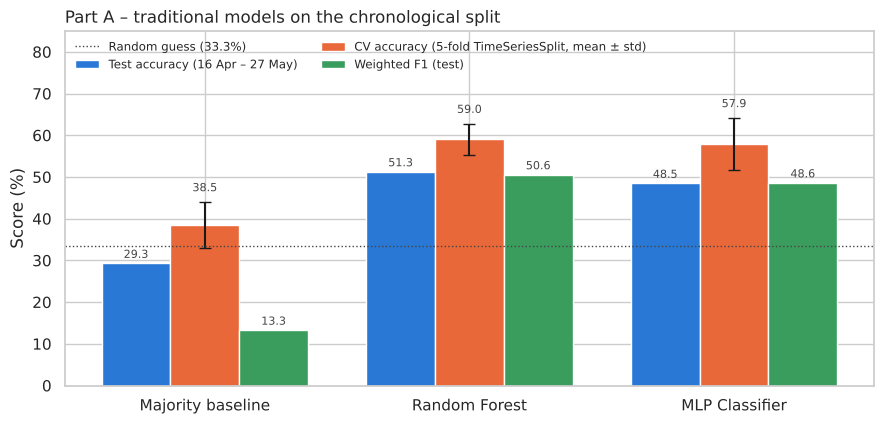

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.4))
names = results_A.index.tolist()
x = np.arange(len(names))
w = 0.26
b1 = ax.bar(x - w, results_A["test_accuracy"] * 100, width=w, color=COLOR_MAIN, label="Test accuracy (16 Apr – 27 May)")
b2 = ax.bar(x, results_A["cv_mean"] * 100, width=w, color=COLOR_SECOND, yerr=results_A["cv_std"] * 100, capsize=4,
            label="CV accuracy (5-fold TimeSeriesSplit, mean ± std)")
b3 = ax.bar(x + w, results_A["weighted_F1"] * 100, width=w, color=COLOR_THIRD, label="Weighted F1 (test)")
for b in (b1, b3):
    ax.bar_label(b, fmt="%.1f", padding=2, fontsize=8, color=COLOR_TEXT)
ax.bar_label(b2, fmt="%.1f", padding=6, fontsize=8, color=COLOR_TEXT)
ax.axhline(100 / 3, color=COLOR_TEXT, linestyle=":", linewidth=1, label="Random guess (33.3%)")
ax.set_xticks(x, names)
ax.set_ylim(0, 85)
ax.set_ylabel("Score (%)")
ax.set_title("Part A – traditional models on the chronological split", loc="left")
ax.legend(loc="upper left", frameon=False, fontsize=8.5, ncols=2)
fig.tight_layout()
save_fig(fig, "pa3_A5_traditional_comparison")
plt.show()

### A.5 observations
- Both models are far above the majority-class baseline (29.3%) and random guessing (33.3%). The Random Forest leads on all three metrics.
- In every group, the orange CV bar is 8–9 pp higher than the blue test bar. This gap measures how much harder the later, warmer test period is than the periods seen in training.
- The longer error bar of the MLP shows that its accuracy changes more from one time block to the next.